# Jakobshavn Isbræ TerraSAR-X Velocities: the Full Series, 2008–2026
---

The companion notebook, `JakobshavnTSXDemo.ipynb`, works with the maps for the Jakobshavn grid **W69.10N** that are
delivered as tar files: a Version 4 update (October 2022 – January 2025) and Version 5 (January 2025 – October 2026). The
earlier maps of the same data set ([NSIDC-0481](https://nsidc.org/data/NSIDC-0481), Version 4, June 2008 – September 2023)
are at NSIDC. The two sources do not overlap: the Version 4 update holds the maps that are not yet at NSIDC. This notebook:

1. finds the Version 4 W69.10N products at NSIDC,
2. reads a subset around the lower glacier and saves it to a NetCDF file, so the download is only done once,
3. reads the same subset of the maps in the two tar files, and
4. plots the full 2008–2026 series at the sample points used in the companion notebook.
5. reads the GrIMP Sentinel-1 6/12-day series (2015–2026) for a larger box that extends 50 km farther inland, and plots it with the TerraSAR-X series.

Version 4 and Version 5 are directly comparable (the processing for a single image pair is the same), so the two parts of
the series can be plotted together without any adjustment. Version 5 starts with pairs whose first image was acquired on or
after 5 January 2025.

## Environment Setup

As for the companion notebook, the GrIMP notebook environment (`binder/environment.yml` in
[GrIMPNotebooks](https://github.com/fastice/GrIMPNotebooks)) provides everything needed. Reading from NSIDC requires an
[EarthData](https://urs.earthdata.nasa.gov) login (see below). Run the companion notebook first, or at least keep the
two tar files in this directory: the cell that reads the local maps unpacks them if needed.

## Python Setup

In [1]:
import nisardev as nisar
import grimpfunc as grimp
import os
import glob
import tarfile
import requests
import numpy as np
import pyproj
import matplotlib.pyplot as plt
from datetime import datetime

## Files and Area of Interest

To keep the download and the NetCDF file small, only a 20 x 30 km box around the lower glacier and the sample points is read
(about 0.5 GB for all of the Version 4 maps). The box and the points are in polar stereographic coordinates (EPSG:3413).

In [2]:
ncFile = 'JakobshavnTSX_v04.nc'  # saved Version 4 subset
tarFiles = ['Version4-update-through-December2024_Wcoast-69.10N.tar',  # Version 4 maps not yet at NSIDC
            'Version5-update-through-October2026_Wcoast-69.10N.tar']
box = 'W69.10N'
localDir = None  # directory holding already-downloaded NSIDC files; None reads them from NSIDC (see below)
xyBounds = {'minx': -186000, 'maxx': -166000, 'miny': -2293000, 'maxy': -2263000}
#
points = {'Lower trunk (DLR 2023 Fig. 1)': (69.1243, -49.5317),
          'Upper trunk': (69.1191, -49.2642),
          'Northern branch': (69.2371, -49.5418),
          'Southern margin': (69.0246, -49.4446)}
lat, lon = np.array(list(points.values())).transpose()
xPts, yPts = pyproj.Transformer.from_crs(4326, 3413).transform(lat, lon)
colors = ['r', 'm', 'c', 'darkorange']

## Login to EarthData/NSIDC

Reading the data from NSIDC requires an EarthData login. If the NetCDF file from an earlier run already exists, or the files
have already been downloaded (`localDir`, see below), nothing is downloaded and the login is skipped. GDAL is also told to retry requests that NSIDC refuses when it receives too many
at once.

In [3]:
haveNC = os.path.exists(ncFile)
if not haveNC and localDir is None:
    env = dict(GDAL_HTTP_COOKIEFILE=os.path.expanduser('~/.grimp_download_cookiejar.txt'),
               GDAL_HTTP_COOKIEJAR=os.path.expanduser('~/.grimp_download_cookiejar.txt'),
               GDAL_HTTP_MAX_RETRY='10', GDAL_HTTP_RETRY_DELAY='5')  # retry when NSIDC throttles requests
    os.environ.update(env)
    myLogin = grimp.NASALogin()  # If login appears not to work, try rerunning this cell
    display(myLogin.view())
else:
    print(f'{ncFile} exists, skipping login')

JakobshavnTSX_v04.nc exists, skipping login


## Find the Version 4 Products at NSIDC

The products are found with a search of NASA's Common Metadata Repository (CMR), limited to the W69.10N box by its name.
Each product has several files (vx, vy, vv, ex, ey, browse and metadata); as in the other GrIMP notebooks, the read routines
take one name per product with a wildcard (`*`) for the band and no `.tif` extension. Results are requested page by page
using CMR's `search-after` header.

In [4]:
def searchCMR(shortName, version, filePattern, firstDate='2008-01-01', lastDate='2026-12-31', pageSize=2000):
    ''' Return the data URLs for all granules matching filePattern '''
    params = {'provider': 'NSIDC_CPRD', 'short_name': shortName, 'version': version,
              'temporal[]': f'{firstDate}T00:00:00Z,{lastDate}T23:59:59Z',
              'producer_granule_id[]': filePattern, 'options[producer_granule_id][pattern]': 'true',
              'sort_key[]': 'start_date', 'page_size': pageSize}
    headers, urls = {}, []
    while True:
        response = requests.get('https://cmr.earthdata.nasa.gov/search/granules.json', params=params, headers=headers)
        response.raise_for_status()
        entries = response.json()['feed']['entry']
        for entry in entries:
            urls += [link['href'] for link in entry.get('links', [])
                     if 'data#' in link.get('rel', '') and not link.get('inherited', False)]
        if len(entries) < pageSize or 'CMR-Search-After' not in response.headers:
            return sorted(set(urls))
        headers['CMR-Search-After'] = response.headers['CMR-Search-After']


if not haveNC and localDir is None:
    urls = searchCMR('NSIDC-0481', '4', f'*{box}*')
    myCogs = [u.replace('_vx_', '_*_').replace('.tif', '') for u in urls if u.endswith('_vx_v04.0.tif')]
    print(f'{len(myCogs)} Version 4 products for {box}')
    print(myCogs[0])

### Using Files Already Downloaded

If the Version 4 GeoTIFFs have already been downloaded (e.g., with the NSIDC download script or Earthdata Search), they can be
read from disk instead:

1. Set `localDir` in the *Files and Area of Interest* cell above to the directory that holds them. The files can be in any
   subdirectory layout below it; the next cell searches it recursively.
2. The product names are conditioned the same way as the URLs: the band (`vx`) is replaced with the wildcard `*` and the
   `.tif` extension is removed, e.g. `/data/NSIDC-0481/TSX_W69.10N_12Jun08_23Jun08_10-05-11_*_v04.0`. Each product needs its
   `vx` and `vy` files (plus `ex` and `ey` if errors are read).
3. The reads below then use `url=False` (set automatically when `localDir` is given), and no login is needed.

In [5]:
if not haveNC and localDir is not None:
    vxFiles = sorted(glob.glob(f'{localDir}/**/TSX_{box}_*_vx_v04.0.tif', recursive=True))
    myCogs = [f.replace('_vx_', '_*_').replace('.tif', '') for f in vxFiles]
    print(f'{len(myCogs)} Version 4 products for {box} in {localDir}')
    print(myCogs[0])

## Read the Version 4 Maps and Save Them

The maps are read in batches of 25: each batch is opened lazily, cut to the box, read (`loadRemote`) and saved to its own
NetCDF file in `v04batches/`. NSIDC occasionally refuses a request when it receives many at once, which shows up as a file
that cannot be opened; a batch that fails is simply retried after a pause. Batches already saved are skipped, so if the
download is interrupted, rerunning the cell picks up where it stopped. The batches are then combined into the single NetCDF
file, which later runs read instead (the `v04batches/` directory can be deleted after that). The whole download takes
roughly 15–30 minutes for the ~700 maps.

In [6]:
import time
import xarray as xr


def readBatch(cogs, batchFile, xyBounds, url=True, maxTries=5, wait=60):
    ''' Read one batch of products (from NSIDC if url, else from disk), cut to xyBounds, and save it; retry if NSIDC
    refuses a request '''
    for attempt in range(1, maxTries + 1):
        try:
            batch = nisar.nisarVelSeries(numWorkers=1)  # one request at a time, so NSIDC does not refuse them
            batch.readSeriesFromTiff(cogs, url=url, readSpeed=False)
            batch.subsetVel(xyBounds)
            batch.loadRemote()
            batch.toNetCDF(batchFile)
            return
        except Exception as e:
            print(f'{batchFile}: attempt {attempt} failed ({str(e)[:80]}...), retrying in {wait} s')
            time.sleep(wait)
    raise RuntimeError(f'{batchFile}: failed after {maxTries} attempts')


if not haveNC:
    batchDir, batchSize = 'v04batches', 25
    os.makedirs(batchDir, exist_ok=True)
    batchFiles = []
    for k in range(0, len(myCogs), batchSize):
        batchFile = f'{batchDir}/batch{k:04d}.nc'
        if not os.path.exists(batchFile):
            readBatch(myCogs[k:k + batchSize], batchFile, xyBounds, url=localDir is None)
        batchFiles.append(batchFile)
        print(f'{min(k + batchSize, len(myCogs))} of {len(myCogs)} products done', end='\r')
    # Combine the batches into one series and save it
    parts = []
    for batchFile in batchFiles:
        batch = nisar.nisarVelSeries()
        batch.readSeriesFromNetCDF(batchFile)
        batch.loadRemote()
        parts.append(batch.subset)
    batch.subset = xr.concat(parts, dim='time').sortby('time')  # products are in first-date order; sort by mid date
    batch.toNetCDF(ncFile)
    print(f'\nSaved {ncFile} ({os.path.getsize(ncFile) / 1e6:.0f} MB)')
#
v4Series = nisar.nisarVelSeries()
v4Series.readSeriesFromNetCDF(ncFile)
v4Series.loadRemote()
print(f'Version 4 from NSIDC: {len(v4Series.time)} maps, mid dates {v4Series.time[0]:%Y-%m-%d} to '
      f'{v4Series.time[-1]:%Y-%m-%d}')

Version 4 from NSIDC: 693 maps, mid dates 2008-06-17 to 2023-09-03


## Read the Local Maps

The maps in the two tar files are unpacked here only if that has not been done already (e.g. by the companion notebook),
read as one series (they share the same grid), and cut to the same box.

In [7]:
for tarFile in tarFiles:
    with tarfile.open(tarFile) as tf:
        members = [m for m in tf.getmembers() if m.isfile()]
        if all(os.path.exists(m.name) and os.path.getsize(m.name) == m.size for m in members):
            print(f'{tarFile} already unpacked')
        else:
            tf.extractall('.', filter='data')
            print(f'Unpacked {len(members)} files from {tarFile}')
#
vvFiles = sorted(glob.glob('Version*-update-through-*/Wcoast-69.10N/Vel.*/*_vv_v0?.0.tif'),
                 key=lambda f: os.path.basename(os.path.dirname(f)))
localSeries = nisar.nisarVelSeries()
localSeries.readSeriesFromTiff([f.replace('_vv_', '_*_').replace('.tif', '') for f in vvFiles], url=False,
                               readSpeed=False)
localSeries.subsetVel(xyBounds)
localSeries.loadRemote()
print(f'Local: {len(localSeries.time)} maps, mid dates {localSeries.time[0]:%Y-%m-%d} to {localSeries.time[-1]:%Y-%m-%d}')

Version4-update-through-December2024_Wcoast-69.10N.tar already unpacked
Version5-update-through-October2026_Wcoast-69.10N.tar already unpacked
Local: 113 maps, mid dates 2022-11-05 to 2026-09-29


## Maps from the Start and the End of the Series

The first summer map with good coverage of the box in 2009 (NSIDC) and in 2026 (Version 5), with the sample points:

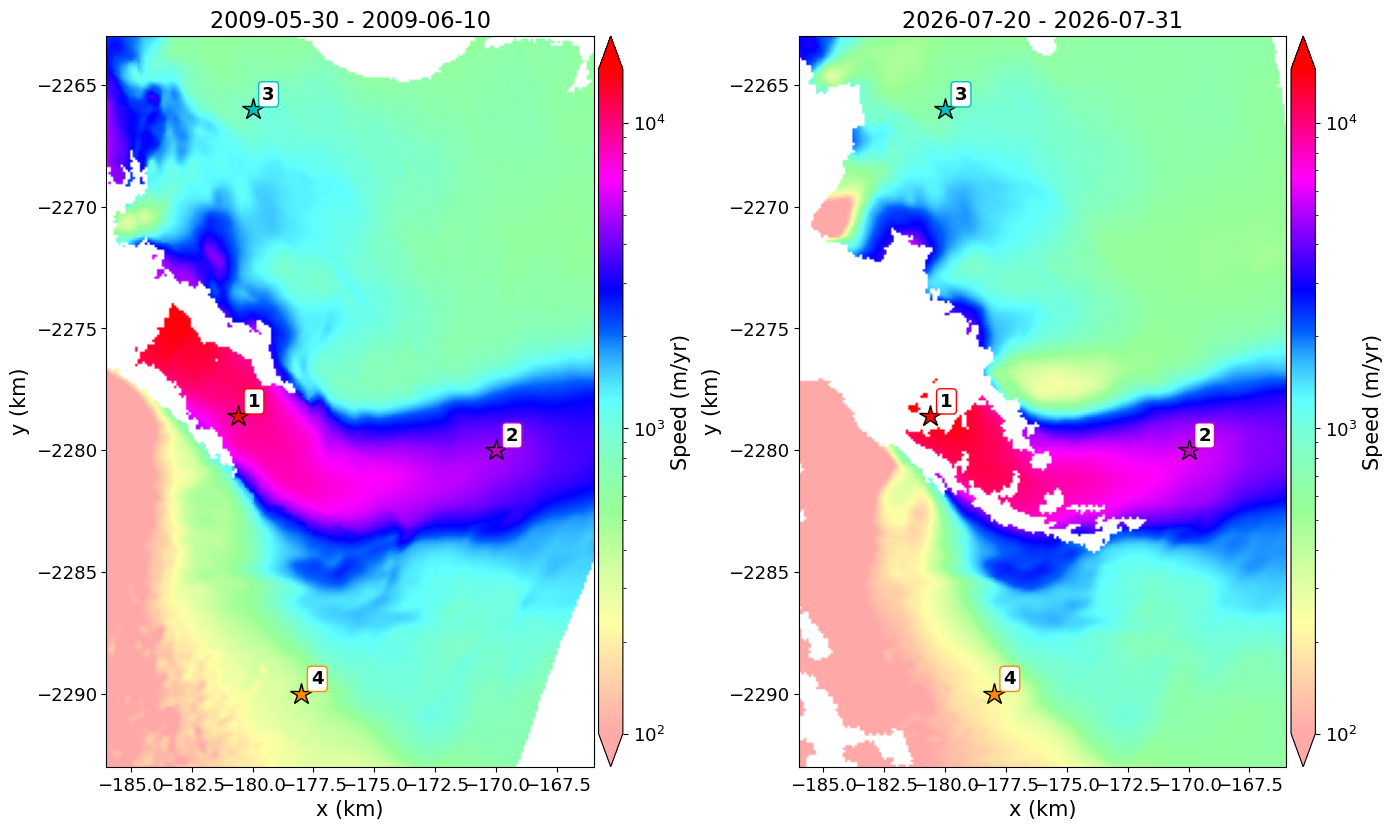

In [8]:
def firstGoodDate(series, year, minCoverage=0.8):
    ''' First map in June-September of year with valid speed over most of the box '''
    for date, vv in zip(series.time, series.vv):
        if date.year == year and 6 <= date.month <= 9 and np.mean(np.isfinite(vv)) >= minCoverage:
            return date
    return None


fig, axes = plt.subplots(1, 2, figsize=(14, 9))
for ax, series, year in zip(axes, [v4Series, localSeries], [2009, 2026]):
    date = firstGoodDate(series, year) or series.time[0]
    series.displayVelForDate(date=date, ax=ax, units='km', vmin=100, vmax=15000, scale='log', midDate=False)
    for k, (x, y, c) in enumerate(zip(xPts, yPts, colors)):
        ax.plot(x / 1000, y / 1000, '*', color=c, markersize=16, markeredgecolor='k')
        ax.annotate(str(k + 1), (x / 1000, y / 1000), xytext=(7, 7), textcoords='offset points', fontsize=13,
                    fontweight='bold', bbox=dict(boxstyle='round,pad=0.2', fc='white', ec=c))
fig.tight_layout()

## The Full Series at the Sample Points

`interp` samples every map in each series at the points (given as latitude/longitude with `sourceEPSG=4326`). Maps from
NSIDC are plotted as small dots, the Version 4 update as filled circles and Version 5 as open circles.

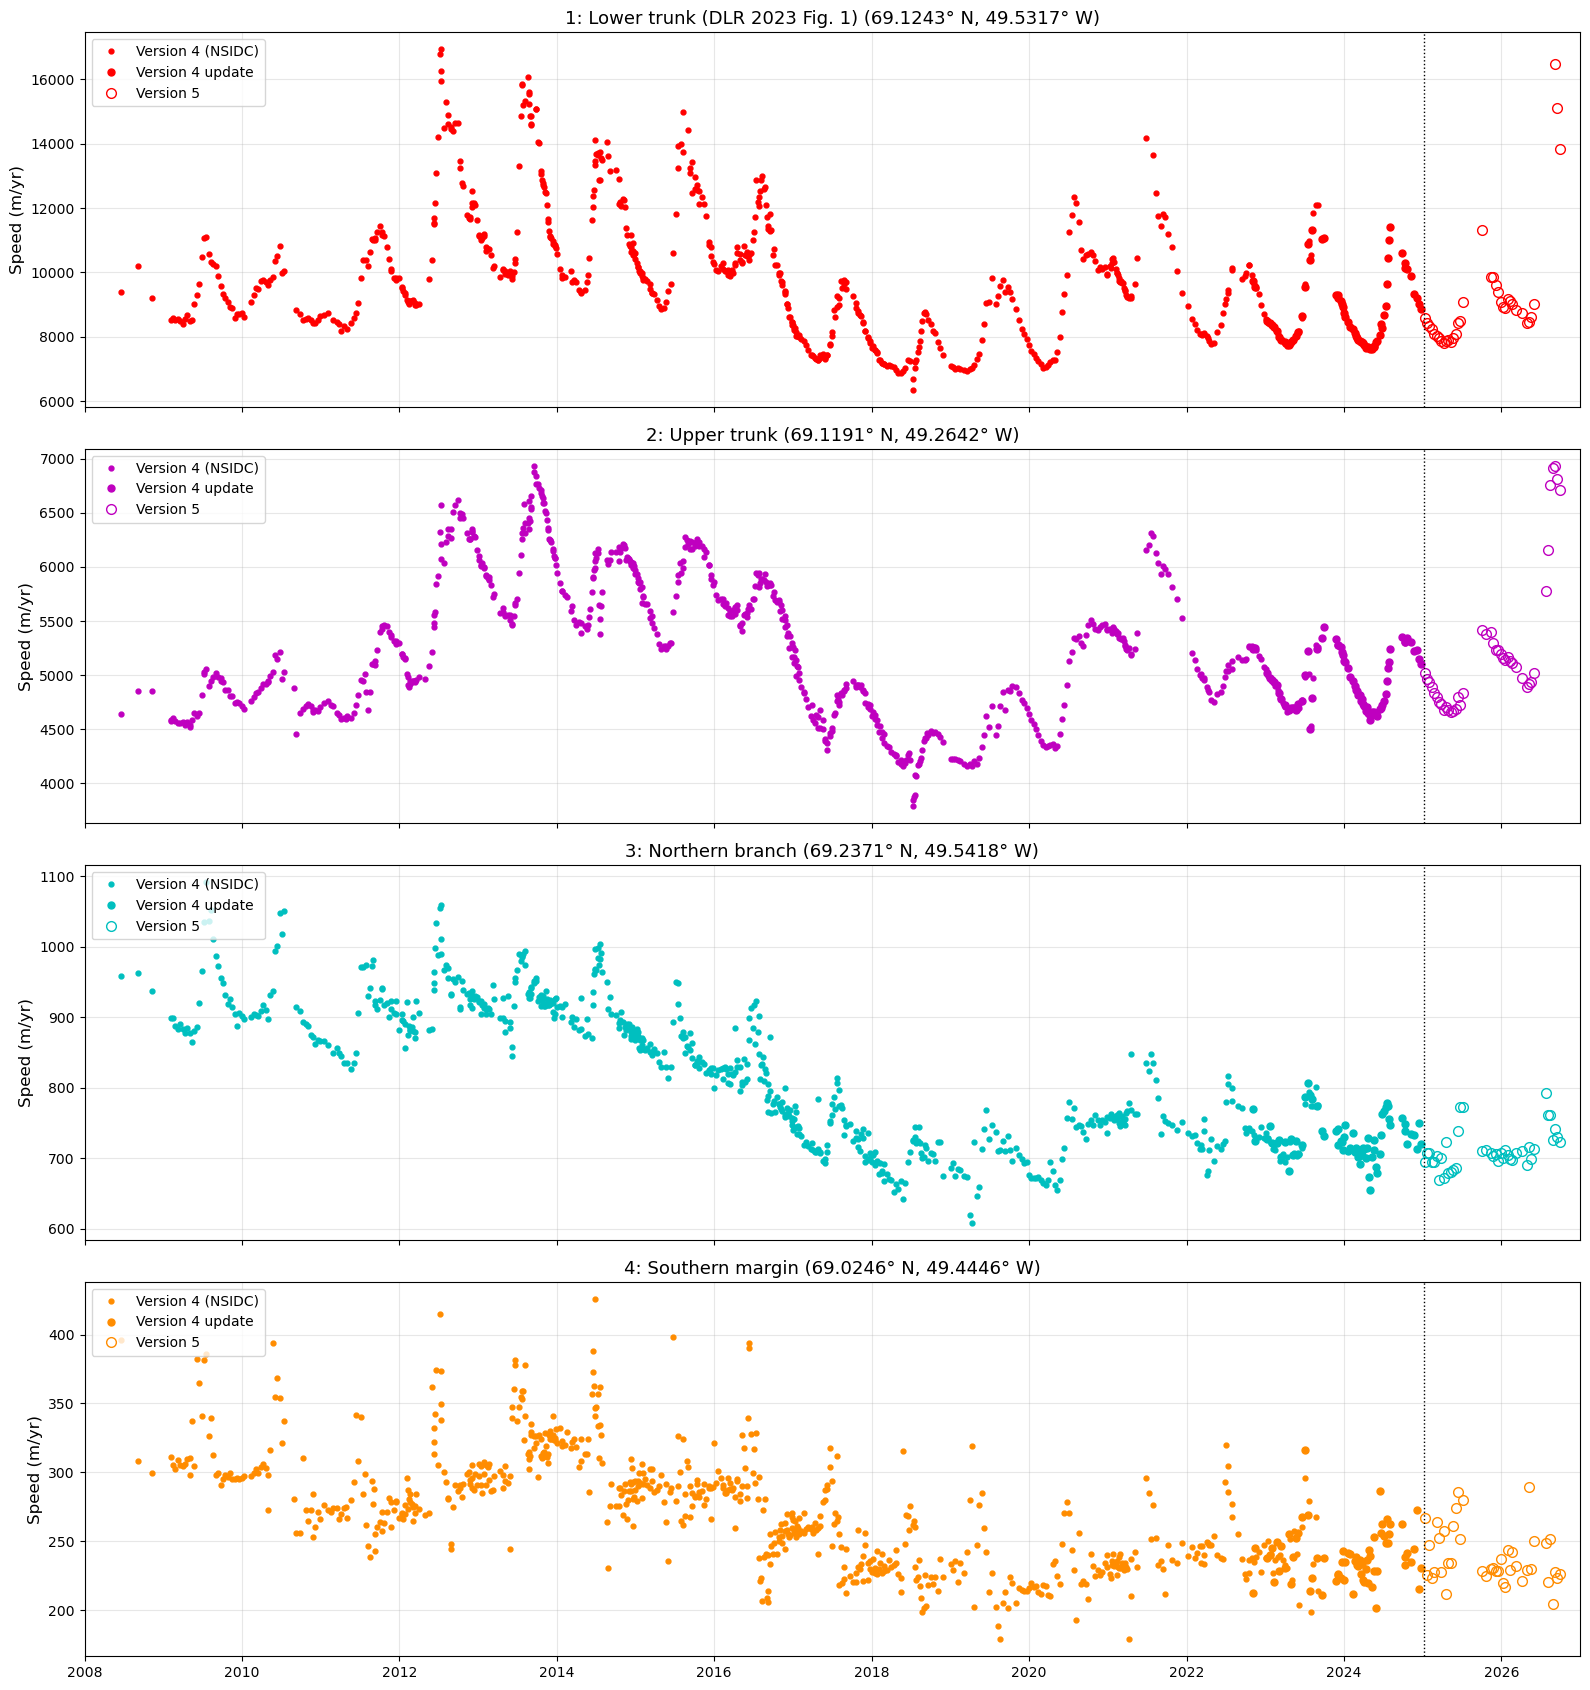

In [9]:
_, _, vvNSIDC = v4Series.interp(lat, lon, sourceEPSG=4326)
_, _, vvLocal = localSeries.interp(lat, lon, sourceEPSG=4326)
localTimes = np.array(localSeries.time)
isV5 = localTimes >= datetime(2025, 1, 5)
#
fig, axes = plt.subplots(4, 1, figsize=(16, 17), sharex=True)
for i, (name, ax, c) in enumerate(zip(points, axes, colors)):
    ax.plot(v4Series.time, vvNSIDC[:, i], '.', color=c, markersize=7, label='Version 4 (NSIDC)')
    ax.plot(localTimes[~isV5], vvLocal[~isV5, i], 'o', color=c, markersize=5, label='Version 4 update')
    ax.plot(localTimes[isV5], vvLocal[isV5, i], 'o', color=c, markerfacecolor='none', markersize=7, label='Version 5')
    ax.axvline(datetime(2025, 1, 5), color='k', linestyle=':', linewidth=1)
    ax.set_title(f'{i + 1}: {name} ({lat[i]:.4f}° N, {-lon[i]:.4f}° W)', fontsize=13)
    ax.set_ylabel('Speed (m/yr)', fontsize=12)
    ax.grid(True, alpha=0.3)
    ax.legend(loc='upper left')
axes[-1].set_xlim(datetime(2008, 1, 1), datetime(2027, 1, 1))
fig.tight_layout()

The dotted line marks 5 January 2025, the start of Version 5. Point 1 is close to the calving front, so it has no data while
the front is retreated behind it (typically late summer), and it shows the large seasonal and multi-year changes of the
terminus region. The points farther upstream follow the same pattern with smaller amplitudes.

## The Sentinel-1 6/12-Day Series

The file `JakobshavnS1_v06.nc` holds the GrIMP Greenland 6/12-day velocity maps (Version 6 processing, the series distributed
by NSIDC as [NSIDC-0766](https://nsidc.org/data/NSIDC-0766)), mostly from Sentinel-1, cut to a box around Jakobshavn Isbræ.
The box covers the TerraSAR-X W69.10N grid and extends 50 km farther inland (x = −220 to −82 km, y = −2318.4 to −2243.4 km).
It has 516 maps at 200 m resolution, from 1 January 2015 to 18 September 2026:

* each map covers a fixed 12-day window (6-day windows from 28 September 2016 to 22 December 2021, when both Sentinel-1A
  and 1B were operating) and includes all of the image pairs whose center dates fall in the window, so each map is dated
  at the center of its window;
* the bands are vx, vy and the speed (vv), and their errors (ex, ey, ev), all in m/yr. The speed error is the error of the
  magnitude of the vector, $e_v = \sqrt{(v_x e_x)^2 + (v_y e_y)^2}/v$.

The file was written with nisardev, so it is read the same way as the TerraSAR-X NetCDF file above.

In [10]:
s1File = 'JakobshavnS1_v06.nc'
s1Series = nisar.nisarVelSeries()
s1Series.readSeriesFromNetCDF(s1File)
s1Series.loadRemote()
print(f'Sentinel-1: {len(s1Series.time)} maps, center dates {s1Series.time[0]:%Y-%m-%d} to '
      f'{s1Series.time[-1]:%Y-%m-%d}, bands {[str(b) for b in s1Series.variables]}')

Sentinel-1: 516 maps, center dates 2015-01-06 to 2026-09-12, bands ['vx', 'vy', 'vv', 'ex', 'ey', 'ev']


### A Summer Map of the Whole Box

The summer 2024 map with the most coverage of the box, with the outline of the TerraSAR-X W69.10N grid (solid), the smaller box
read from the TerraSAR-X maps above (dashed), the sample points and a fifth point, on the main trunk about 50 km above the
upper-trunk point, that only the Sentinel-1 maps cover.

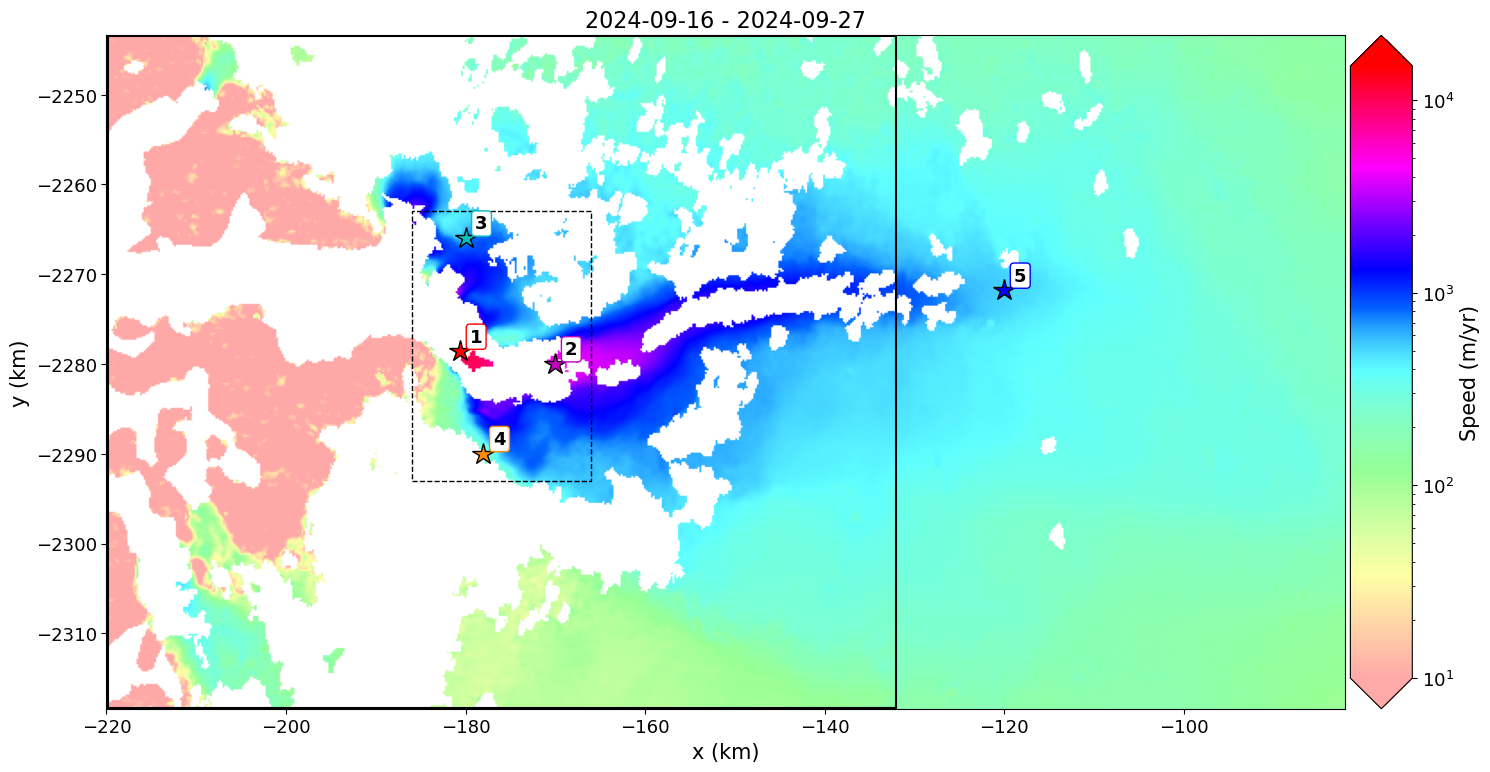

In [11]:
from matplotlib.patches import Rectangle

inlandPoint = ('Inland trunk (Sentinel-1 only)', (69.2207, -48.0236))
latS1 = np.append(lat, inlandPoint[1][0])
lonS1 = np.append(lon, inlandPoint[1][1])
xS1, yS1 = pyproj.Transformer.from_crs(4326, 3413).transform(latS1, lonS1)
colorsS1 = colors + ['b']
namesS1 = list(points) + [inlandPoint[0]]


def bestDate(series, year, months=(6, 7, 8, 9)):
    ''' The map in the given months of year with the most valid speeds '''
    coverage = [np.mean(np.isfinite(vv)) if date.year == year and date.month in months else -1
                for date, vv in zip(series.time, series.vv)]
    return series.time[int(np.argmax(coverage))]


fig, ax = plt.subplots(1, 1, figsize=(15, 9))
s1Series.displayVelForDate(date=bestDate(s1Series, 2024), ax=ax, units='km', vmin=10, vmax=15000, scale='log',
                           midDate=False)
ax.add_patch(Rectangle((-219.85, -2318.35), 87.8, 74.9, fill=False, edgecolor='k', linewidth=1.5))
ax.add_patch(Rectangle((xyBounds['minx'] / 1000, xyBounds['miny'] / 1000), (xyBounds['maxx'] - xyBounds['minx']) / 1000,
                       (xyBounds['maxy'] - xyBounds['miny']) / 1000, fill=False, edgecolor='k', linestyle='--'))
for k, (x, y, c) in enumerate(zip(xS1, yS1, colorsS1)):
    ax.plot(x / 1000, y / 1000, '*', color=c, markersize=16, markeredgecolor='k')
    ax.annotate(str(k + 1), (x / 1000, y / 1000), xytext=(7, 7), textcoords='offset points', fontsize=13,
                fontweight='bold', bbox=dict(boxstyle='round,pad=0.2', fc='white', ec=c))
fig.tight_layout()

### The Sentinel-1 and TerraSAR-X Series at the Sample Points

The Sentinel-1 speeds (black, with their errors) are plotted over the TerraSAR-X speeds (in the point colors, as above) from
2015 on. The two do not measure exactly the same thing: the Sentinel-1 maps are 200 m averages over 6- or 12-day windows,
while the TerraSAR-X maps are 100 m and each spans a single 11-day pair, so they can differ where the speed changes sharply
across the glacier or from one week to the next near the front.

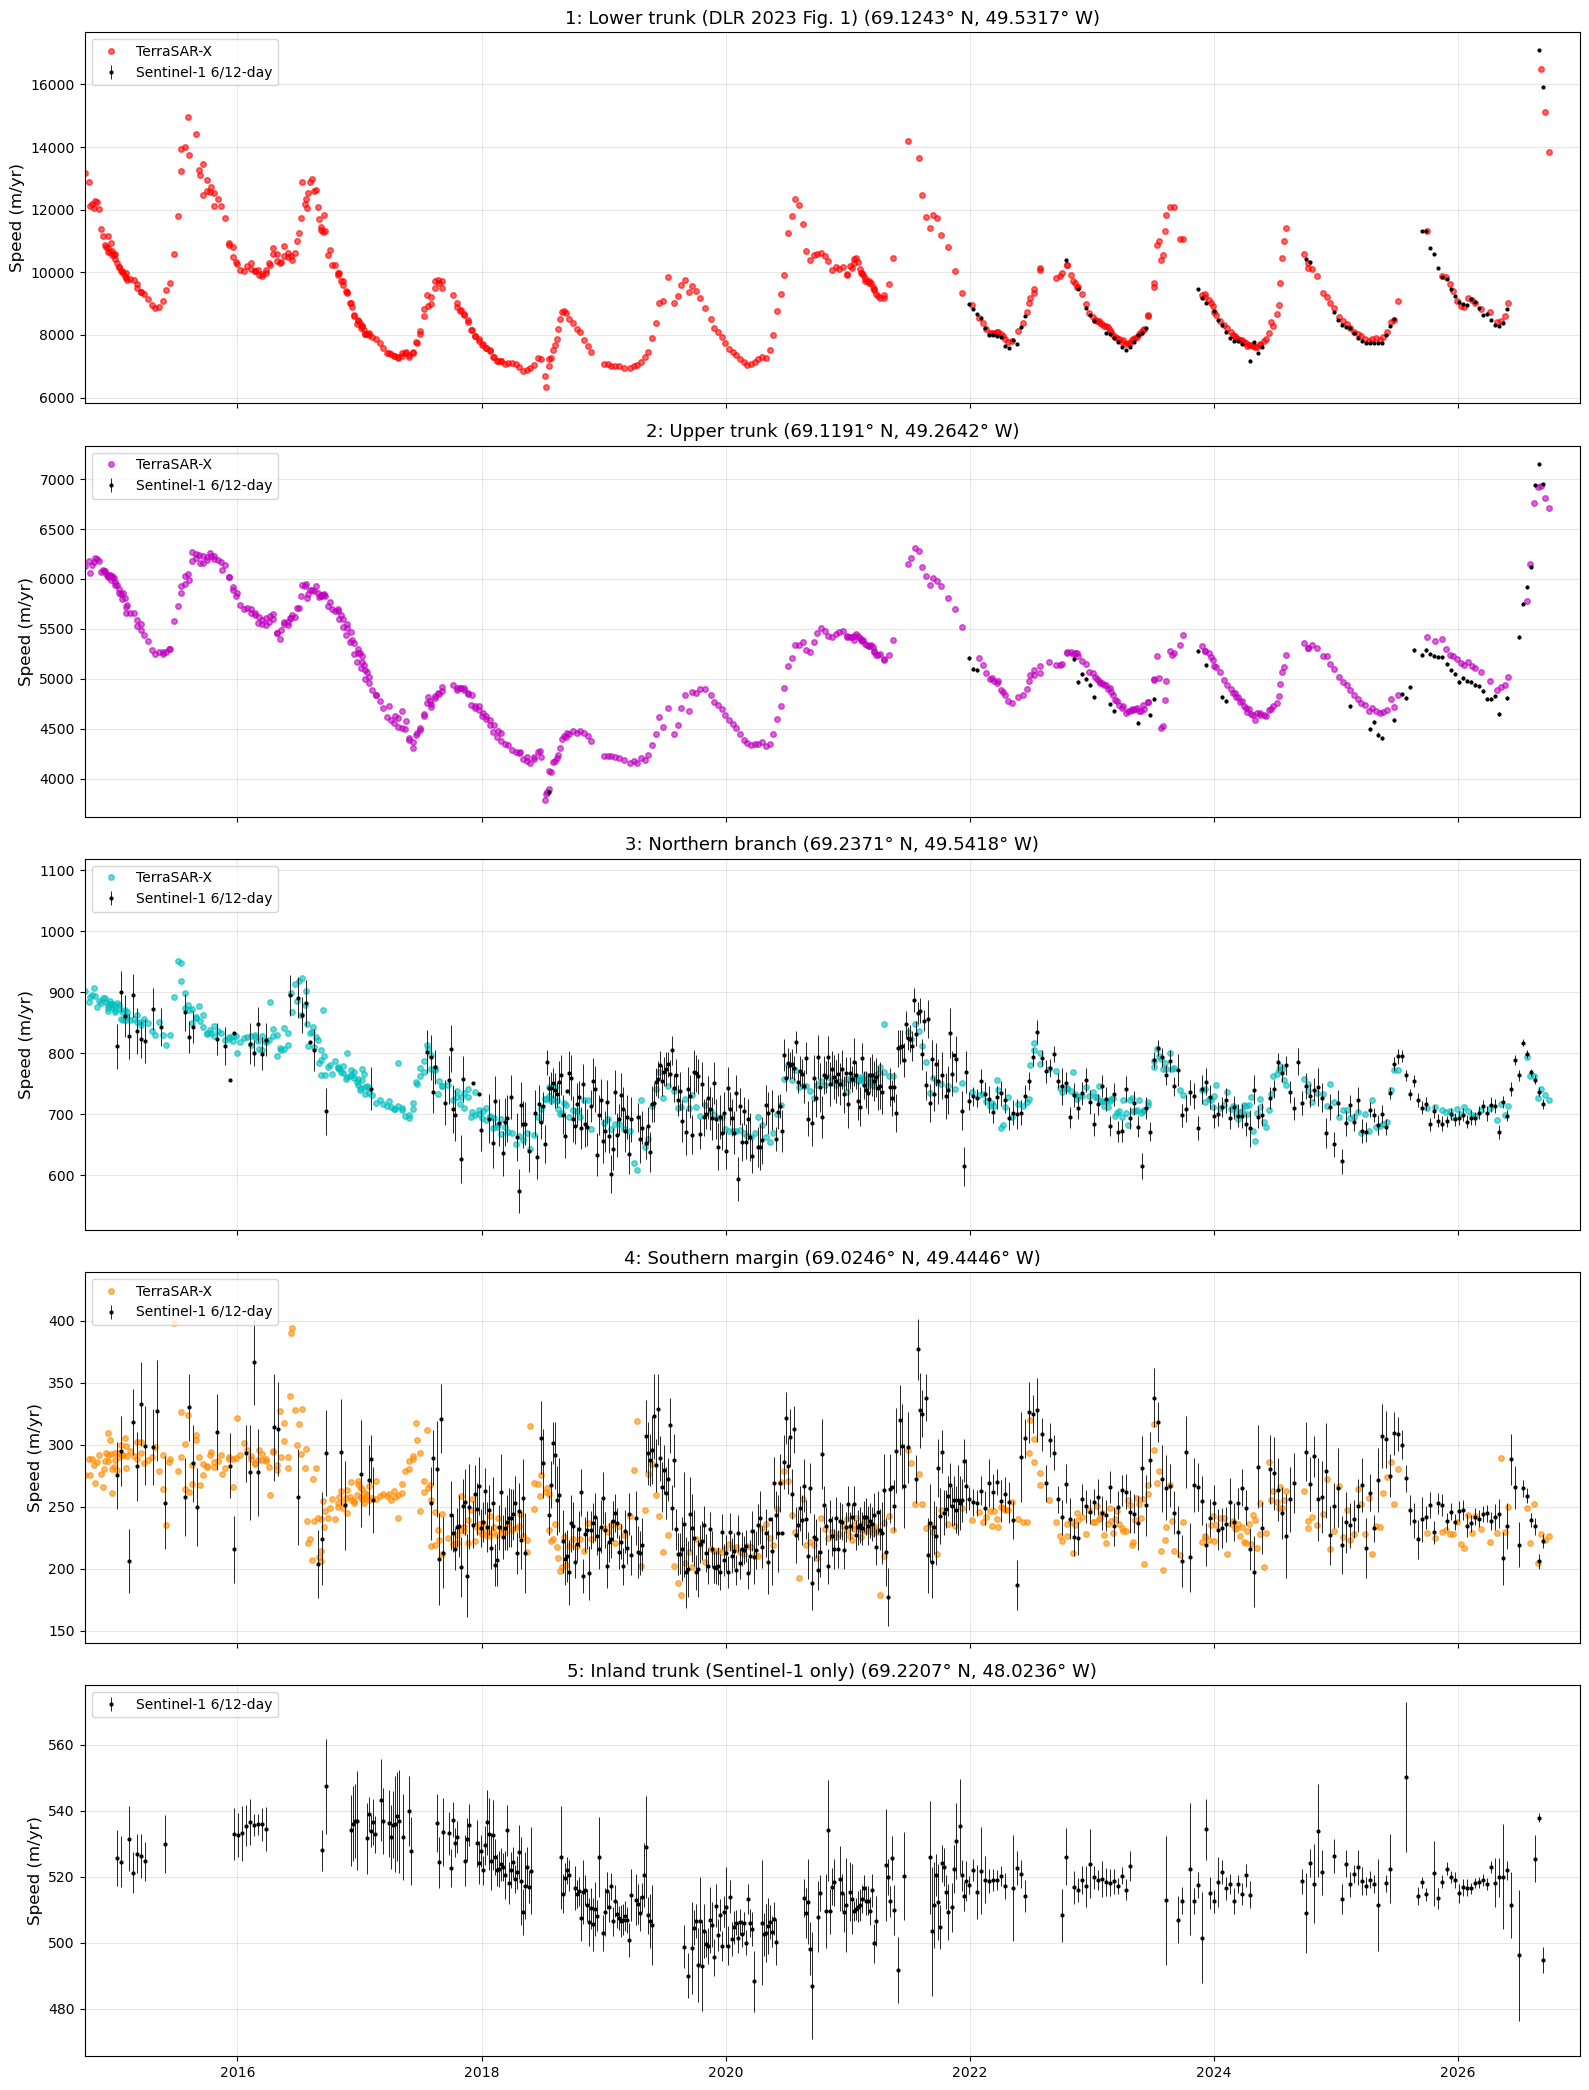

In [12]:
vxS, vyS, vvS, exS, eyS, evS = s1Series.interp(latS1, lonS1, sourceEPSG=4326)
s1Times = np.array(s1Series.time)
tsxTimes = np.concatenate([np.array(v4Series.time), localTimes])
vvTSX = np.concatenate([vvNSIDC, vvLocal])
#
fig, axes = plt.subplots(len(namesS1), 1, figsize=(16, 4.2 * len(namesS1)), sharex=True)
for i, (name, ax, c) in enumerate(zip(namesS1, axes, colorsS1)):
    if i < len(points):
        ax.plot(tsxTimes, vvTSX[:, i], 'o', color=c, markersize=4, alpha=0.6, label='TerraSAR-X')
    ax.errorbar(s1Times, vvS[:, i], yerr=evS[:, i], fmt='.', color='k', markersize=4, elinewidth=0.6,
                label='Sentinel-1 6/12-day')
    ax.set_title(f'{i + 1}: {name} ({latS1[i]:.4f}° N, {-lonS1[i]:.4f}° W)', fontsize=13)
    ax.set_ylabel('Speed (m/yr)', fontsize=12)
    ax.grid(True, alpha=0.3)
    ax.legend(loc='upper left')
axes[-1].set_xlim(datetime(2014, 10, 1), datetime(2027, 1, 1))
fig.tight_layout()